In [610]:
import numpy as np
from matplotlib import pyplot as plt

In [612]:
san_ts=np.load(r'D:\PhD Thesis Writing\Data\2025-09-30\20Mhz_Background_Spectrum_noreceiverfull_30_09_25ts.npy')
san_xs=np.load(r'D:\PhD Thesis Writing\Data\2025-09-30\20Mhz_Background_Spectrum_noreceiverfull_30_09_25xs.npy')
san_ls=np.load(r'D:\PhD Thesis Writing\Data\2025-09-30\20Mhz_Background_Spectrum_noreceiverfull_30_09_25ls.npy')

In [614]:
print(san_ls)

[1.5250e-06 1.5250e-06 1.5250e-06 ... 1.5456e-06 1.5456e-06 1.5456e-06]


In [616]:
(1.5456-1.525)/(0.0001)

206.00000000000173

In [618]:
wavelength=1525
wavelength2=1610

In [620]:
wavelengths=[]
for i in range(851):
    wavelengths.append(wavelength+(i*0.1))

In [622]:
wavelengths2=[]
for i in range(len(wavelengths)):
    index=int(len(wavelengths)-(i+1))
    wavelengths2.append(wavelengths[index])

In [624]:
index=int(-207*5)
san_ls_fixed=san_ls[:index]
san_ts_fixed=san_ts[:index]
san_xs_fixed=san_xs[:index]

In [626]:
san_ls_fixed2=[]
for i in range(int(len(san_ls_fixed)/(5*(len(wavelengths)+len(wavelengths2))))):
    for j in range(len(wavelengths)):
        san_ls_fixed2.append(wavelengths[j])
        san_ls_fixed2.append(wavelengths[j])
        san_ls_fixed2.append(wavelengths[j])
        san_ls_fixed2.append(wavelengths[j])
        san_ls_fixed2.append(wavelengths[j])
    for j in range(len(wavelengths2)):
        san_ls_fixed2.append(wavelengths2[j])
        san_ls_fixed2.append(wavelengths2[j])
        san_ls_fixed2.append(wavelengths2[j])
        san_ls_fixed2.append(wavelengths2[j])
        san_ls_fixed2.append(wavelengths2[j])
for j in range(len(wavelengths)):
        san_ls_fixed2.append(wavelengths[j])
        san_ls_fixed2.append(wavelengths[j])
        san_ls_fixed2.append(wavelengths[j])
        san_ls_fixed2.append(wavelengths[j])
        san_ls_fixed2.append(wavelengths[j])

In [628]:
san_ls=san_ls_fixed2
san_ts=san_ts_fixed
san_xs=san_xs_fixed

In [630]:
san_ns=[]
for i in range(len(san_xs)):
    san_ns.append(i)

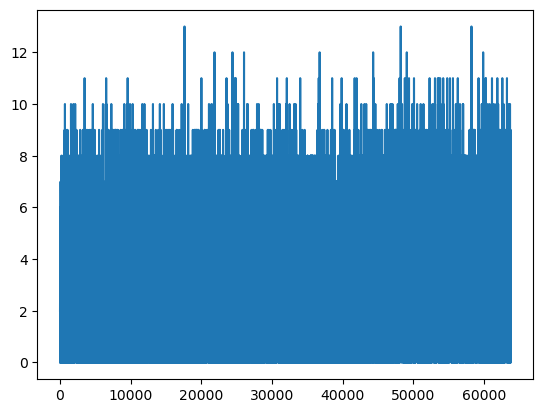

In [632]:
plt.plot(san_ns,san_xs)

In [634]:
ls_ref=wavelengths

In [636]:
san_xs_combined=np.zeros_like(ls_ref)
for i in range(len(ls_ref)):
    for j in range(len(san_ls)):
        if san_ls[j] == ls_ref[i]:
            san_xs_combined[i]=san_xs_combined[i]+san_xs[j]

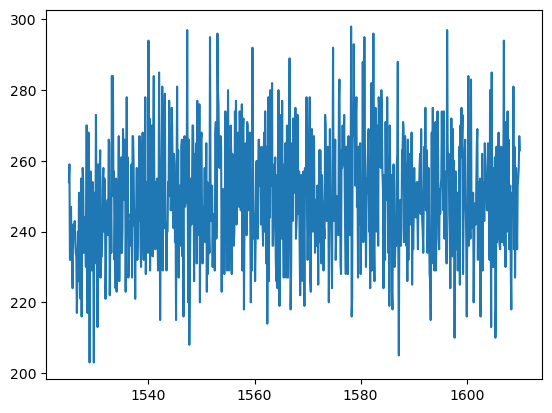

In [638]:
plt.plot(ls_ref,san_xs_combined)

In [640]:
eff=np.load('IDQubeEff.npy')
eff_norm=(eff-np.min(eff))/(np.max(eff)-np.min(eff))
eff_dec=eff/100
san_xs_com_norm=(san_xs_combined*np.mean(eff_dec))/eff_dec

In [642]:
san_xs_ave=[]
san_ts_ave=[]
san_ls_ave=[]
s_xs_var=[]
s_xs_std=[]
for i in range(int(len(san_xs)/5)):
    i1=5*i
    i2=(5*i)+5
    xs_av=np.sum(san_xs[i1:i2])
    xs_var=np.sum(san_xs[i1:i2])
    ts_av=san_ts[(i*5)+2]
    ls_av=np.mean(san_ls[i1:i2])
    san_xs_ave.append(xs_av)
    san_ts_ave.append(ts_av)
    san_ls_ave.append(ls_av)
    s_xs_var.append(xs_var)
    s_xs_std.append(np.sqrt(xs_var))

In [650]:
san_ns_ave=[]
for i in range(len(san_xs_ave)):
    san_ns_ave.append(i)

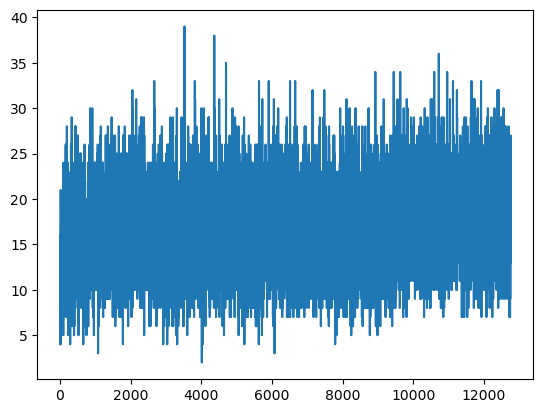

In [654]:
plt.plot(san_ns_ave,san_xs_ave)

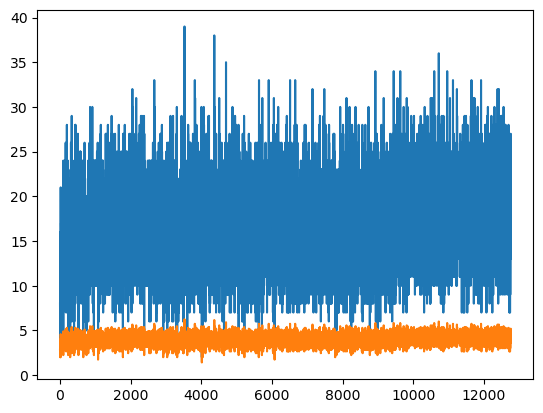

In [656]:
plt.plot(san_ns_ave,s_xs_var)
plt.plot(san_ns_ave,s_xs_std)

In [658]:
san_xs_ave_combined=np.zeros_like(ls_ref)
san_xs_ave_combined_var=np.zeros_like(ls_ref)
for i in range(len(ls_ref)):
    for j in range(len(san_ls_ave)):
        if san_ls_ave[j] == ls_ref[i]:
            san_xs_ave_combined[i]=san_xs_ave_combined[i]+san_xs_ave[j]
            san_xs_ave_combined_var[i]=san_xs_ave_combined_var[i]+s_xs_var[j]
san_xs_ave_combined_std=np.sqrt(san_xs_ave_combined_var)

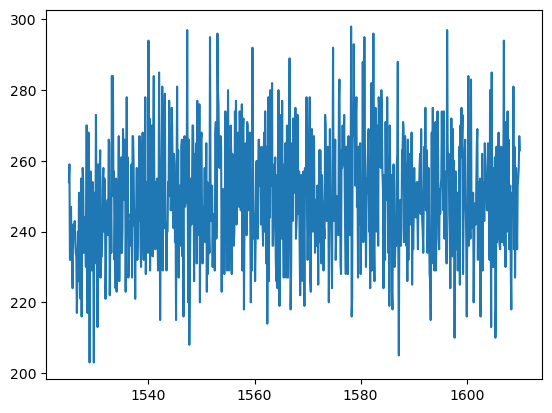

In [660]:
plt.plot(ls_ref,san_xs_ave_combined)

<ErrorbarContainer object of 3 artists>

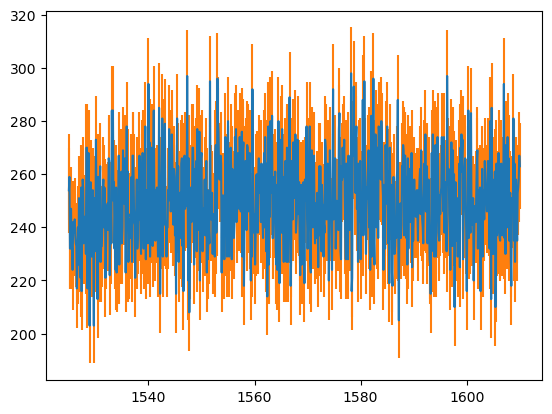

In [698]:
plt.errorbar(ls_ref,san_xs_ave_combined,yerr=san_xs_ave_combined_std,ecolor='tab:orange')

In [662]:
ls_ref_bin=[]
san_xs_bin=[]
san_xs_bin_var=[]
for i in range(int(len(san_xs_ave_combined)/10)):
    i1=10*i
    i2=(10*i)+10
    xs_sum=np.sum(san_xs_ave_combined[i1:i2])
    xs_var=np.sum(san_xs_ave_combined_var[i1:i2])
    ls_av=np.mean(ls_ref[i1:i2])
    san_xs_bin.append(xs_sum)
    ls_ref_bin.append(ls_av)
    san_xs_bin_var.append(xs_var)
san_xs_bin_std=np.sqrt(san_xs_bin_var)

In [664]:
int(len(san_xs_ave_combined)/10)

85

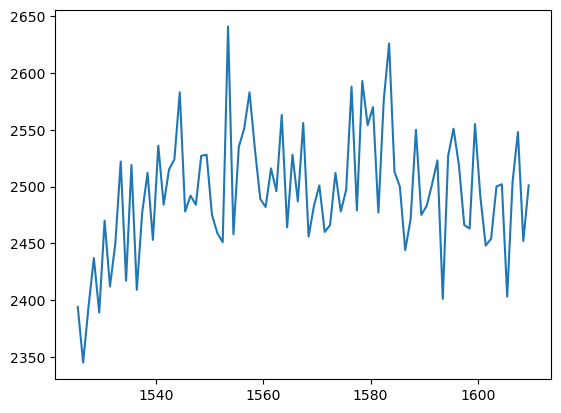

In [668]:
plt.plot(ls_ref_bin,san_xs_bin)

<ErrorbarContainer object of 3 artists>

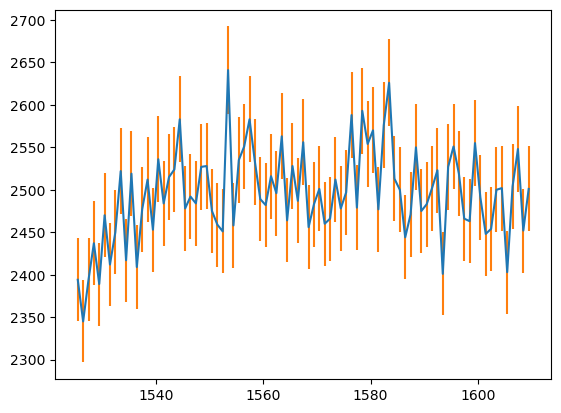

In [700]:
plt.errorbar(ls_ref_bin,san_xs_bin,yerr=san_xs_bin_std,ecolor='tab:orange')

In [708]:
len(san_ls)/len(ls_ref)

75.0

In [704]:
len(ls_ref)

851

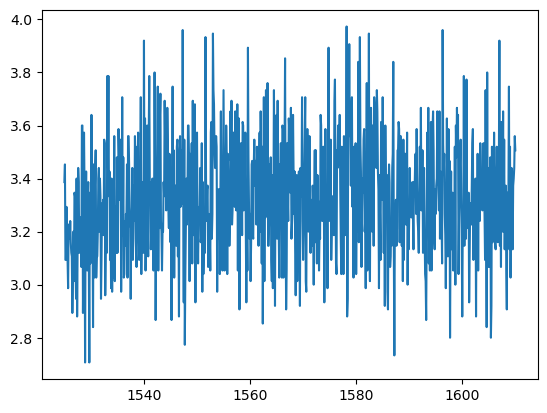

In [710]:
plt.plot(ls_ref,san_xs_ave_combined/75)

<ErrorbarContainer object of 3 artists>

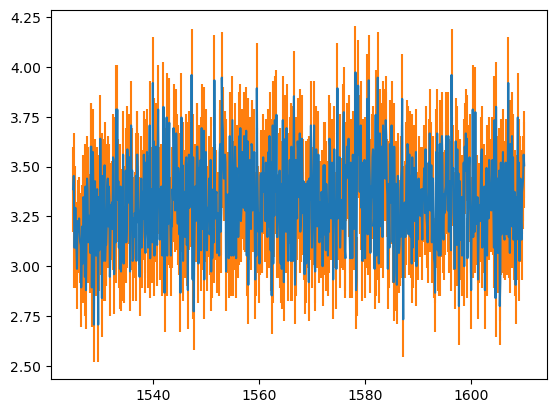

In [712]:
plt.errorbar(ls_ref,san_xs_ave_combined/75,yerr=san_xs_ave_combined_std/75,ecolor='tab:orange')

In [716]:
np.mean(san_xs_ave_combined/75)

3.32695652173913

In [734]:
np.sqrt((np.sum(san_xs_bin_var)/(75**2))/(len(san_xs_ave_combined)**2))

0.007215377102753615